# Chapter 13

Python version of the R code for Chapter 13 of *In All Likelihood* (Pawitan, 2001).

Random numbers are generated with numpy, so simulated results will not
match the R output exactly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, special

from helpers import DATA, approx, qqnorm, qqline

## Figure 13.1 (`FIG13-1.R`)

support for zero
0.0057610092346320795
support for zero
0.11959803906092488


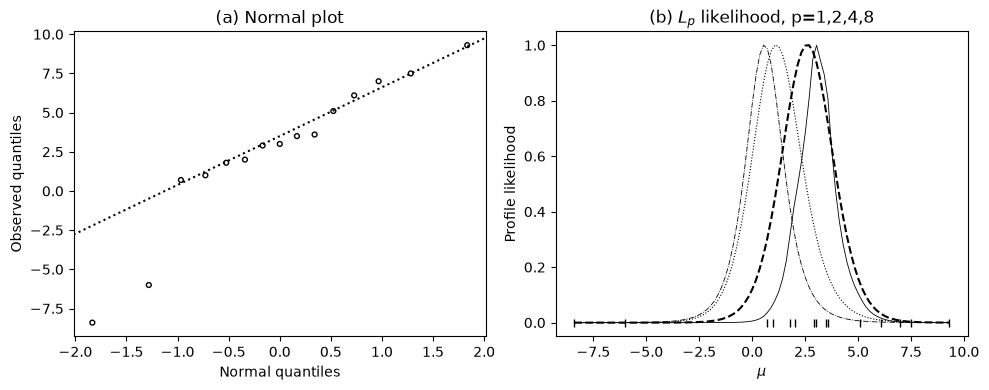

-Log L(p), in page 367:   42.88891153075849 44.023137476940434 44.677889492444784 44.50259288479072


In [2]:
x = np.loadtxt(DATA / "darwin.dat")
x = x[:, 1] - x[:, 2]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
q, s = qqnorm(x)
ax.scatter(q, s, s=12, facecolors="none", edgecolors="k")
qqline(ax, x, color="k", ls=":")
ax.set_xlabel("Normal quantiles")
ax.set_ylabel("Observed quantiles")
ax.set_title("(a) Normal plot")

n = len(x)
mu = np.linspace(x.min(), x.max(), 100)
xbar = x.mean()


def lp_profile(p):
    """Profile log-likelihood of mu under the L_p (generalised normal) model."""
    nsig = (np.abs(x[None, :] - mu[:, None]) ** p).sum(axis=1)
    co = 1 / special.gamma(1 + 1 / p) / 2 ** (1 + 1 / p)  # constant term
    return n * np.log(co) - n / p * np.log(nsig / n * p / 2) - n / p


loglik = lp_profile(1)
m1 = loglik.max()
lik1 = np.exp(loglik - loglik.max())
print("support for zero")
print(approx(mu, lik1, 0))

loglik = lp_profile(2)
m2 = loglik.max()
lik2 = np.exp(loglik - loglik.max())
print("support for zero")
print(approx(mu, lik2, 0))

loglik = lp_profile(4)
m4 = loglik.max()
lik4 = np.exp(loglik - loglik.max())

loglik = lp_profile(8)
m8 = loglik.max()
lik8 = np.exp(loglik - loglik.max())

ax = axes[1]
ax.plot(mu, lik1, "k-", lw=0.6)
ax.plot(mu, lik2, "k--")
ax.plot(x, np.zeros(n), "k|", ms=6)
ax.plot(mu, lik4, "k:", lw=0.8)
ax.plot(mu, lik8, "k-.", lw=0.6)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("Profile likelihood")
ax.set_title(r"(b) $L_p$ likelihood, p=1,2,4,8")
fig.tight_layout()
plt.show()

# profile over p
print("-Log L(p), in page 367:  ", -m1, -m2, -m4, -m8)

## Example 13.2 (`EX13-2.R`)

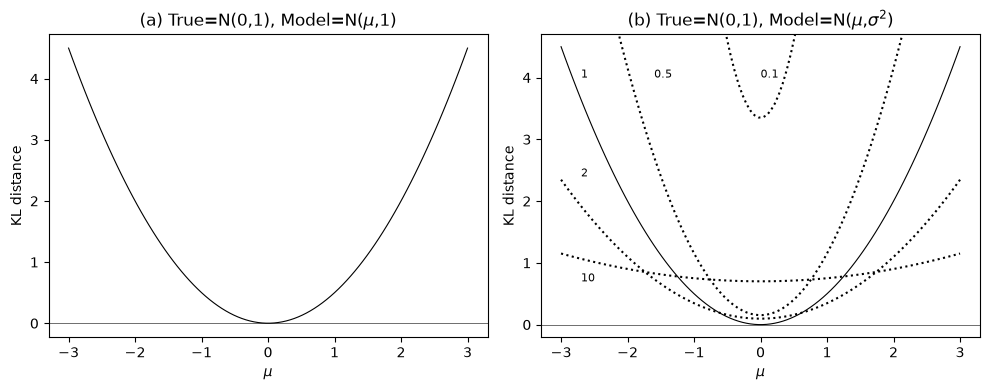

In [3]:
def kl(mu, sig):
    """KL distance from N(0,1) to N(mu, sig)."""
    return (np.log(sig) + (mu ** 2 + 1) / sig - 1) / 2


mu = np.linspace(-3, 3, 100)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(mu, kl(mu, 1), "k-", lw=0.8)
ax.axhline(0, color="k", lw=0.4)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("KL distance")
ax.set_title(r"(a) True=N(0,1), Model=N($\mu$,1)")

ax = axes[1]
ax.plot(mu, kl(mu, 1), "k-", lw=0.8)
ax.text(-2.7, 4, "1", fontsize=8)
ax.axhline(0, color="k", lw=0.4)
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("KL distance")
ax.set_title(r"(b) True=N(0,1), Model=N($\mu$,$\sigma^2$)")
for sig, (tx, ty) in [(2, (-2.7, 2.4)), (10, (-2.7, .7)), (.5, (-1.6, 4)), (.1, (0, 4))]:
    ax.plot(mu, kl(mu, sig), "k:", lw=1.5)
    ax.text(tx, ty, str(sig), fontsize=8)
ax.set_ylim(kl(mu, 1).min() - 0.2, kl(mu, 1).max() + 0.2)  # axes set by the sigma=1 curve, as in R
fig.tight_layout()
plt.show()

## Example 13.3 (`EX13-3.R`)

Distance to gamma.

0.09074868487156929


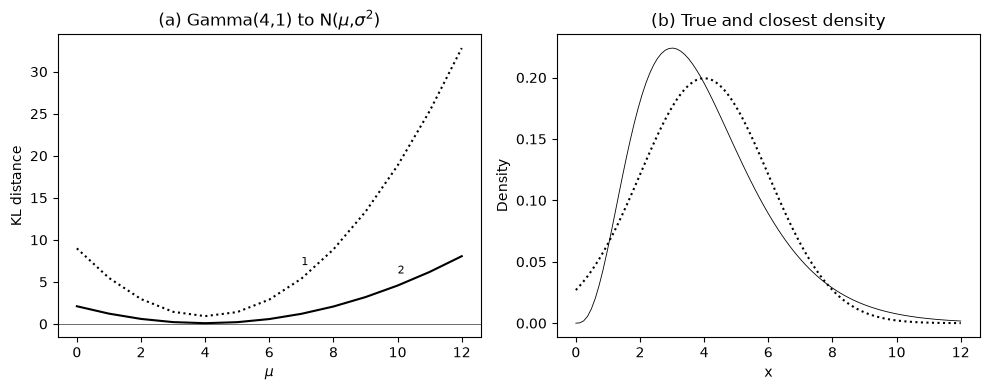

In [4]:
rng = np.random.default_rng(13)

bt = 4
x = rng.gamma(bt, size=10000)
meang = np.mean(np.log(stats.gamma.pdf(x, bt)))
mu = np.arange(0, 13)
sig = np.sqrt(bt)

kl = np.array([meang - np.mean(np.log(stats.norm.pdf(x, m, sig))) for m in mu])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ax = axes[0]
ax.plot(mu, kl, "k-")
print(kl.min())
ax.set_xlabel(r"$\mu$")
ax.set_ylabel("KL distance")
ax.set_title(r"(a) Gamma(4,1) to N($\mu$,$\sigma^2$)")

sig = 1
kl = np.array([meang - np.mean(np.log(stats.norm.pdf(x, m, sig))) for m in mu])
ax.plot(mu, kl, "k:", lw=1.5)
ax.axhline(0, color="k", lw=0.4)
ax.text(7, 7, "1", fontsize=8)
ax.text(10, 6, "2", fontsize=8)

x = np.linspace(0, 12, 100)
ax = axes[1]
ax.plot(x, stats.gamma.pdf(x, bt), "k-", lw=0.6)
ax.plot(x, stats.norm.pdf(x, bt, np.sqrt(bt)), "k:", lw=1.5)
ax.set_xlabel("x")
ax.set_ylabel("Density")
ax.set_title("(b) True and closest density")
fig.tight_layout()
plt.show()

## Example 13.7 (`EX13-7.R`)

In [5]:
x = np.array([-5.2, -1.9, -1.0, -0.7, -0.3, 0.0, 0.4, 0.5, 2.3, 3.3])

# normal
l1 = np.sum(np.log(stats.norm.pdf(x, 0, 1)))
print("normal log-lik= ", l1)

# Cauchy:
l2 = np.sum(np.log(stats.cauchy.pdf(x, 0, 1)))
print("Cauchy log-lik= ", l2)

normal log-lik=  -33.59938533204673
Cauchy log-lik=  -22.173482112274836
